# Homework 03 (Bandit): Coding

Nome Cognome: Luca Simonelli

Confronteremo le seguenti tecniche di *reinforced learning*

1.  Epsilon-Greedy;
2.  UCB1 (Upper confidence sampling);
3.  Thompson sampling, eventualmente modificato opportunamente.

Per fare ciò, useremo la classe `BanditGame` discussa a lezione.

In [24]:
### SI PUO' CAMBIARE QUESTA PARTE ###
nameApp = "HW03_Bandit"
NameDir = "HW_03"

dirIn = "/Users/giacomoaletti/Downloads/" + NameDir
dirOut = "/Users/giacomoaletti/Downloads/Data/"

Indaco = True

# set Indaco Directories
if Indaco:
    import pathlib

    # set Indaco Directories
    dirOut = str(pathlib.Path().resolve()) + "/" + NameDir + "/"
    pathOut = pathlib.Path(dirOut)
    if not pathOut.exists():
        pathOut.mkdir(parents=True)

    dirIn = str(pathlib.Path().resolve().parent) + "/data/" + NameDir + "/"

In [25]:
# Let's import the libraries we will need
import polars as pl
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

import sys
sys.path.insert(0, dirIn)

import bandit_classes as bc

Obiettivo è confrontare le strategie sopra avendo a disposizione $T = 10\,000$ (`numTrials`) in diversi contesti con a disposizione $4$ arms possibili (`numArms`).  
Come seed prenderemo ``"HW03_Bandit"``.  
Per testare il codice conviene mettere ``numTrials = 1_000`` (tipo).

In [26]:
# parameter setting
numTrials = 10_000
numArms = 4
seed = "HW03_Bandit"

### Strategia $\epsilon$-Greedy (vista a lezione)

Le strategie Greedy e $\epsilon$-greedy vengono copiate da quelle viste a lezione. Si cambia la probabilità dell'esplorazione, sempre mantenendola dell'ordine di $1/t$ (può essere cambiata)

In [27]:
from random import Random


class GreedyBandit(bc.BanditGame):

    def __init__(self, numArms=None, seed=None, func=None, numInitialized=1):
        super().__init__(numArms=numArms, numPulled=0, seed=seed, func=func)
        # random generator for choice when multiple max
        self._rnd_internal1 = Random(x=self._pullRandom + self._pullRandom)
        # initialization
        print(f"Initialization with {numInitialized} pulls for each arm")
        _ = super().pull(numArms="all", numPulled=numInitialized)

    def greedy_choiche(self):
        # get the mean rewards so far
        rew = self.getStats()
        # best performance
        bf = rew.get_column("average").max()
        # filter the best arms
        bA = rew.filter(pl.col("average") == bf).get_column("numArm").to_list()

        # random choice if more than one have the best berformances so far
        if len(bA) > 1:
            bA = self._rnd_internal1.choice(bA)
        return bA

    def best_choice(self):
        return self.greedy_choiche()

    def pull_gen(self, nTimes=1):
        for s in range(nTimes):
            if (s % 100) == 0:
                print(f"t={s} out of {nTimes}")
            # choice of the preferred arm
            bestarm = self.best_choice()
            _ = super().pull(numArms=bestarm)


class EpsGreedyBandit(GreedyBandit):

    def __init__(self, numArms=None, seed=None, func=None, numInitialized=1):
        super().__init__(numArms, seed, func, numInitialized)
        # random generator for exploration vs exploitation
        self._rnd_expl_vs_expo = Random(
            x=self._pullRandom + self._pullRandom + self._pullRandom
        )

    def tot_time(self):
        return len(self.getHistoryRewards(toPolars=False))

    def best_choice(self):
        a = 12
        b = 32
        # exploration or exploitation?
        exploration = self._rnd_expl_vs_expo.random() < b / (a + self.tot_time())
        if exploration:
            return self._rnd_expl_vs_expo.choice(
                [l["numArm"] for l in self.getStats(toPolars=False)]
            )
        else:
            return self.greedy_choiche()

## Strategie UCB e Thompson Sampling (progettazione classi), 5pts

> Si richiede la descrizione dell'idea per implementare le classi delle strategie UCB1 e Thompson Sampling.

---
<!-- Inizia qui la risposta -->
Per implementare le classi UCB1 e Thompson Sampling, dobbiamo modificare il modo in cui l'algoritmo sceglie leva migliore ad ogni iterazione.

**UCB1 (Upper Confidence Bound)**:L'idea è bilanciare esplorazione ed efficacia/exploitation basandosi sull'incertezza. Invece di guardare solo la media dei reward ($\hat{\mu}_i$), calcoliamo per ogni leva un indice che rappresenta il limite superiore dell'intervallo di confidenza:$$UCB_i = \hat{\mu}_i + \alpha \sqrt{\frac{2 \ln T}{N_i}}$$Dove $T$ è il numero totale di giocate e $N_i$ è il numero di volte che la leva $i$ è stata tirata. 

La classe deve calcolare questo valore per tutte le leve e scegliere quella con il valore massimo.

**Thompson Sampling (TS)**:Questo è un approccio Bayesiano. Assumiamo che la probabilità di successo di ogni leva segua una distribuzione Beta (poiché i reward sono spesso modellati come Bernoulli o comunque limitati tra 0 e 1).

Manteniamo due parametri per ogni leva: $\alpha$ (successi + 1) e $\beta$ (fallimenti + 1).
Ad ogni step, invece di usare la media empirica, campioniamo un valore casuale dalla distribuzione $Beta(\alpha_i, \beta_i)$ per ogni leva.Scegliamo la leva che ha generato il campione più alto.

Dopo aver osservato il reward reale, aggiorniamo i parametri $\alpha$ e $\beta$ di quella leva.
<!-- Termina qui la risposta -->
---

## Strategie UCB e Thompson Sampling (codice), 10pts

> Modificare le funzioni di scelta per ciascuna classe


### Strategia UCB1

> Modificare la funzione ``UCB_choice`` per creare la classe ``UCBBandit`` che valuta la miglior leva con strategia *UCB1*


In [28]:
import math
from random import Random
import polars as pl

def UCB_choice(self):
    alpha = 0.25  # Tuning parameter for exploration
    # get the stats so far (columns: numArm, numPlayed, average, sum)
    rew = self.getStats()
    
    # Calculate total time T (sum of all pulls)
    tTot = rew.get_column("numPlayed").sum()
    
    # Avoid log(0) error if tTot is 0 (initialization handles this, but safety first)
    if tTot == 0:
        tTot = 1

    # t[1] is numPlayed, t[2] is average.
    # We add a small epsilon to t[1] to avoid division by zero during calc if not initialized
    band2 = rew.map_rows(
        lambda t: t + (t[2] + alpha * math.sqrt(2 * math.log(tTot) / (t[1] if t[1] > 0 else 1)),)
    )
    
    # Rename the new column to 'rnd' (which acts as the score/index here)
    band2.columns = rew.columns + ["rnd"]

    # best performance (Max UCB value)
    bf = band2.get_column("rnd").max()
    
    # filter the best arms
    bA = band2.filter(pl.col("rnd") == bf).get_column("numArm").to_list()

    # random choice if more than one have the same best performance
    if len(bA) > 1:
        bA = self._rnd_internal1.choice(bA)
    return bA


# from here, classic definition
class UCBBandit(bc.BanditGame):

    def __init__(self, numArms=None, seed=None, func=None, numInitialized=1):
        super().__init__(numArms=numArms, numPulled=0, seed=seed, func=func)
        # random generator for choice when multiple max
        self._rnd_internal1 = Random(x=self._pullRandom + self._pullRandom)
        # Initialization
        print(f"Initialization with {numInitialized} pulls for each arm")
        _ = super().pull(numArms="all", numPulled=numInitialized)

    def best_choice(self):
        return self.UCB_choice()

    def pull_gen(self, nTimes=1):
        for s in range(nTimes):
            if (s % 100) == 0:
                pass # Removed print to keep output clean, add back if needed
            # choice of the preferred arm
            bestarm = self.best_choice()
            _ = super().pull(numArms=bestarm)

UCBBandit.UCB_choice = UCB_choice

### Strategia Thompson sampling

> Modificare la funzione ``TS_choice`` per creare la classe ``TSBandit`` che valuta la miglior leva con strategia *Thompson sampling*

In [29]:
from random import Random
import polars as pl

def TS_choice(self):
    # get the stats (numArm, numPlayed, average, sum)
    # We expect 'sum' (total reward) to be present or calculated. 
    # If getStats returns [numArm, numPlayed, average], then sum = average * numPlayed
    rew = self.getStats()
    
    # Using map_rows. t[1] = numPlayed, t[2] = average. 
    # So t[1]*t[2] is roughly the sum of rewards.
    
    band2 = rew.map_rows(
        lambda t: t + (self._rnd_internal2.betavariate(1 + (t[1]*t[2]), 1 + (t[1] - (t[1]*t[2]))),)
    )
    
    band2.columns = rew.columns + ["rnd"]

    # best performance (Max Sampled value)
    bf = band2.get_column("rnd").max()
    
    # filter the best arms
    bA = band2.filter(pl.col("rnd") == bf).get_column("numArm").to_list()

    # random choice if more than one
    if len(bA) > 1:
        bA = self._rnd_internal1.choice(bA)
    return bA


# from here, classic definition
class TSBandit(bc.BanditGame):

    def __init__(self, numArms=None, seed=None, func=None, numInitialized=1):
        super().__init__(numArms=numArms, numPulled=0, seed=seed, func=func)
        # random generator for choice when multiple max
        self._rnd_internal1 = Random(x=self._pullRandom + self._pullRandom)
        # random generator for arm selection (Beta sampling)
        self._rnd_internal2 = Random(
            x=self._pullRandom + self._pullRandom + self._pullRandom
        )
        # initialization
        print(f"Initialization with {numInitialized} pulls for each arm")
        _ = super().pull(numArms="all", numPulled=numInitialized)

    def best_choice(self):
        return self.TS_choice()

    def pull_gen(self, nTimes=1):
        for s in range(nTimes):
            if (s % 100) == 0:
                pass 
            bestarm = self.best_choice()
            _ = super().pull(numArms=bestarm)

TSBandit.TS_choice = TS_choice

## Esecuzione algoritmo con strategie differenti

Ora il codice segue quanto visto a lezione, e simula il bandit con le 3 diverse tecniche.

In [30]:
# definition and initialization of bandits
grEps = EpsGreedyBandit(numArms=numArms, seed=seed)
grUCB = UCBBandit(numArms=numArms, seed=seed)
grTS = TSBandit(numArms=numArms, seed=seed)

New arm n.0 just now defined!
New arm n.1 just now defined!
New arm n.2 just now defined!
New arm n.3 just now defined!
Initialization with 1 pulls for each arm
New arm n.0 just now defined!
New arm n.1 just now defined!
New arm n.2 just now defined!
New arm n.3 just now defined!
Initialization with 1 pulls for each arm
New arm n.0 just now defined!
New arm n.1 just now defined!
New arm n.2 just now defined!
New arm n.3 just now defined!
Initialization with 1 pulls for each arm


In [31]:
%%capture
# suppress output
print("\nPlay with different strategies\n")

print("\nPlay with EpsGreedy strategy")
grEps.pull_gen(nTimes=numTrials)
print("\nPlay with UCB strategy")
grUCB.pull_gen(nTimes=numTrials)
print("\nPlay with TS strategy")
grTS.pull_gen(nTimes=numTrials)

Vengono plottate, come a lezione, le differenti performance delle tre strategie.

shape: (30_012, 4)
┌───────┬─────────────────┬────────┬──────────┐
│ time  ┆ mean of Rewards ┆ numArm ┆ strategy │
│ ---   ┆ ---             ┆ ---    ┆ ---      │
│ i64   ┆ f64             ┆ i64    ┆ str      │
╞═══════╪═════════════════╪════════╪══════════╡
│ 1     ┆ 0.540945        ┆ 0      ┆ Eps      │
│ 2     ┆ 0.330167        ┆ 1      ┆ Eps      │
│ 3     ┆ 0.553445        ┆ 2      ┆ Eps      │
│ 4     ┆ 0.632344        ┆ 3      ┆ Eps      │
│ 5     ┆ 0.695938        ┆ 3      ┆ Eps      │
│ …     ┆ …               ┆ …      ┆ …        │
│ 10000 ┆ 0.595337        ┆ 3      ┆ TS       │
│ 10001 ┆ 0.595377        ┆ 3      ┆ TS       │
│ 10002 ┆ 0.595405        ┆ 3      ┆ TS       │
│ 10003 ┆ 0.595396        ┆ 3      ┆ TS       │
│ 10004 ┆ 0.595375        ┆ 3      ┆ TS       │
└───────┴─────────────────┴────────┴──────────┘


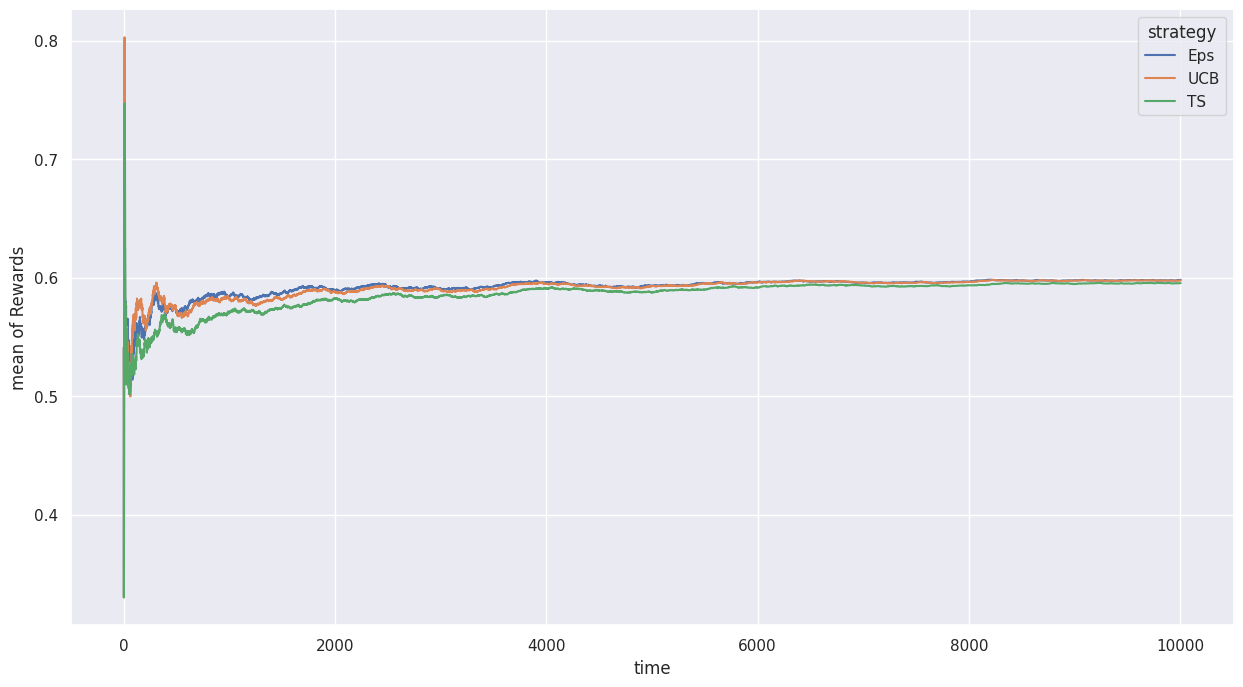

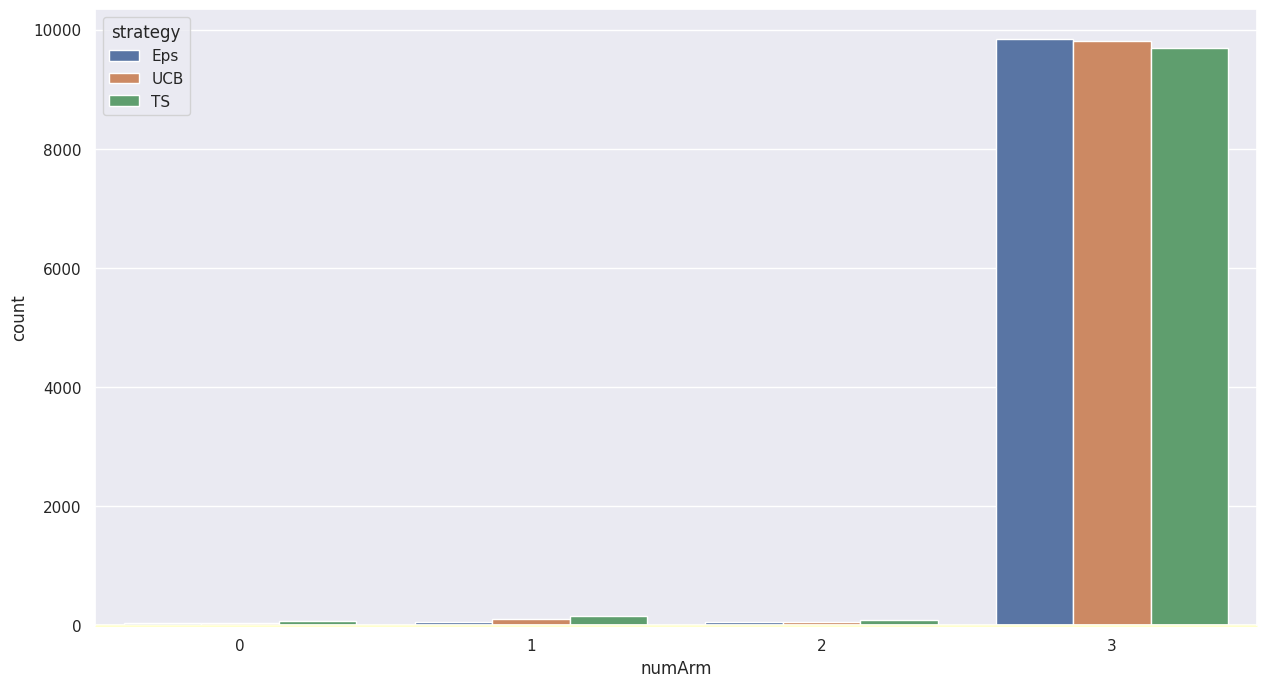

In [32]:
strategies = ["Eps", "UCB", "TS"]

DataPlot = pl.concat(
    [
        globals()[f"gr{strat}"]
        .getHistoryRewards()
        .sort("time")
        .select(
            pl.col("time"),
            (pl.col("reward").cum_sum() / pl.col("time")).alias("mean of Rewards"),
            pl.col("numArm"),
            pl.lit(strat).alias("strategy"),
        )
        for strat in strategies
    ]
)

print(DataPlot)

plt.figure(1, figsize=[15, 8])
# Apply the default theme

sns.set_theme()

# Create a visualization
g = sns.lineplot(data=DataPlot, x="time", y="mean of Rewards", hue="strategy")


# Build a rectangle for initialization phase
left, width = 0, (numArms + 1)
bottom, top = min(DataPlot.get_column("mean of Rewards")), max(
    DataPlot.get_column("mean of Rewards")
)
right = left + width
height = top - bottom
p = plt.Rectangle((left, bottom), width, height, fill=True, color="yellow")

p.set_clip_on(False)
g.add_patch(p)

plt.show()


### second figure

plt.figure(2, figsize=[15, 8])
# Apply the default theme

sns.set_theme()

g = sns.countplot(data=DataPlot, x="numArm", hue="strategy")

# Build a rectangle for initialization phase
left, width = -.5, (numArms)
bottom, top = 0, 1
right = left + width
height = top - bottom
p = plt.Rectangle((left, bottom), width, height, fill=True, color="yellow")
p.set_clip_on(False)

# Apply the default theme
g.axes.add_patch(p)

plt.show()

## Confronto performance, 5pts

> Commentare le performance ottenute.
---
<!-- Inizia qui la risposta -->
L'obiettivo dei tre algoritmi è massimizzare il reward medio cumulato nel tempo, ottimizzando il bilanciamento tra \textit{exploration} ed \textit{exploitation}.

**Epsilon-Greedy ($\epsilon$-Greedy)**:
È la strategia più intuitiva ma presenta dei limiti strutturali. Nonostante identifichi rapidamente una leva buona, la sua natura stocastica forzata (parametro $\epsilon$) la costringe a continuare l'esplorazione casuale anche quando la leva ottimale è individuata. Questo genera un regret che impedisce alla curva del reward medio di raggiungere il valore massimo teorico, stabilizzandosi su un livello inferiore rispetto agli altri metodi.

**UCB1 (Upper Confidence Bound)**:
Implementa il principio dell'ottimismo a fronte dell'incertezza. A differenza di $\epsilon$-greedy, l'esplorazione è guidata dalla varianza delle stime:
$$ UCB_i = \hat{\mu}_i + \alpha \sqrt{\frac{2 \ln T}{N_i}} $$
Inizialmente la curva è più instabile poiché l'algoritmo testa sistematicamente tutte le leve con alta incertezza. Man mano che il tempo $T$ aumenta, il bonus di esplorazione decade, permettendo all'algoritmo di convergere con precisione verso la best arm.

**Thompson Sampling (TS)**: 
Sfruttando la statistica Bayesiana, TS campiona i reward attesi per ogni leva. Questo permette un'esplorazione tale che: le leve sub-ottimali vengono abbandonate molto più rapidamente rispetto a UCB1, riducendo drasticamente il regret totale.

In conclusione, mentre l'$\epsilon$-greedy è efficace per la semplicità computazionale, Thompson Sampling garantisce la massimizzazione del profitto nel minor tempo possibile.
<!-- Termina qui la risposta -->
---

## Intoxicazione (progettazione), 10pts

Si assuma che le quattro leve del bandit siano quattro farmaci differenti di cui non conosciamo gli effetti collaterali, e che le ogni volta che \`\`tiriamo una leva'' stiamo somministrando un farmaco a un nuovo paziente.  
Abbiamo una complicanza ogniqualvolta il reward della somministrazione è minore di $0.2$. 

> Come andrebbe modificato l'algoritmo in modo da minimizzare le complicanze viste, sempre in un numero massimo di $10\,000$ somministrazioni? È necessario modificare le classi?
---
<!-- Inizia qui la risposta -->
Per minimizzare le complicanze (reward $< 0.2$) mantenendo l'obiettivo di trovare la cura migliore, dobbiamo modificare la funzione di reward percepita dall'algoritmo (il parametro func). Se voglio che l'algoritmo eviti le leve che causano intossicazione, devo assegnare un reward molto basso o nullo quando l'evento "reward < 0.2" si verifica.
Invece di passare il reward ($r$), passo un reward trasformato $f(r)$:$$f(r) =
\begin{cases}
r & \text{se } r \ge 0.2 \\
0 \text{ oppure }r^{10} & \text{se } r < 0.2
\end{cases}$$Non serve quindi modificare le classi.
<!-- Termina qui la risposta -->
---

## Intoxicazione (codice), 5pts
> Modificare il codice sotto in modo da simulare Bandit con processo di intossicazioni.

In [ ]:
# Function to penalize intoxication
# If reward is < 0.2 (intoxication), we return a null reward (penalty)
# Otherwise we return the reward itself.
# 
# Viene implementata solo la versione con reward nullo

def avoid_intoxication(rew):
    if rew < 0.2:
        return 0
    return 1

# definition and initialization of bandits
grEps_Intox = EpsGreedyBandit(
    numArms=numArms, seed=seed, func=avoid_intoxication
)
grUCB_Intox = UCBBandit(
    numArms=numArms, seed=seed, func=avoid_intoxication
)
grTS_Intox = TSBandit(
    numArms=numArms, seed=seed, func=avoid_intoxication
)

New arm n.0 just now defined!
New arm n.1 just now defined!
New arm n.2 just now defined!
New arm n.3 just now defined!
Initialization with 1 pulls for each arm
New arm n.0 just now defined!
New arm n.1 just now defined!
New arm n.2 just now defined!
New arm n.3 just now defined!
Initialization with 1 pulls for each arm
New arm n.0 just now defined!
New arm n.1 just now defined!
New arm n.2 just now defined!
New arm n.3 just now defined!
Initialization with 1 pulls for each arm


Da qui in poi termina il codice

In [34]:
%%capture
# suppress output

print("\nPlay with different strategies\n")

print("\nPlay with EpsGreedy strategy")
grEps_Intox.pull_gen(nTimes=numTrials)
print("\nPlay with UCB strategy")
grUCB_Intox.pull_gen(nTimes=numTrials)
print("\nPlay with TS strategy")
grTS_Intox.pull_gen(nTimes=numTrials)


shape: (30_012, 4)
┌───────┬─────────────────┬────────┬──────────┐
│ time  ┆ mean of Rewards ┆ numArm ┆ strategy │
│ ---   ┆ ---             ┆ ---    ┆ ---      │
│ i64   ┆ f64             ┆ i64    ┆ str      │
╞═══════╪═════════════════╪════════╪══════════╡
│ 1     ┆ 1.0             ┆ 0      ┆ Eps      │
│ 2     ┆ 0.5             ┆ 1      ┆ Eps      │
│ 3     ┆ 0.666667        ┆ 2      ┆ Eps      │
│ 4     ┆ 0.75            ┆ 3      ┆ Eps      │
│ 5     ┆ 0.8             ┆ 3      ┆ Eps      │
│ …     ┆ …               ┆ …      ┆ …        │
│ 10000 ┆ 0.9768          ┆ 0      ┆ TS       │
│ 10001 ┆ 0.976802        ┆ 0      ┆ TS       │
│ 10002 ┆ 0.976805        ┆ 0      ┆ TS       │
│ 10003 ┆ 0.976807        ┆ 0      ┆ TS       │
│ 10004 ┆ 0.976809        ┆ 0      ┆ TS       │
└───────┴─────────────────┴────────┴──────────┘


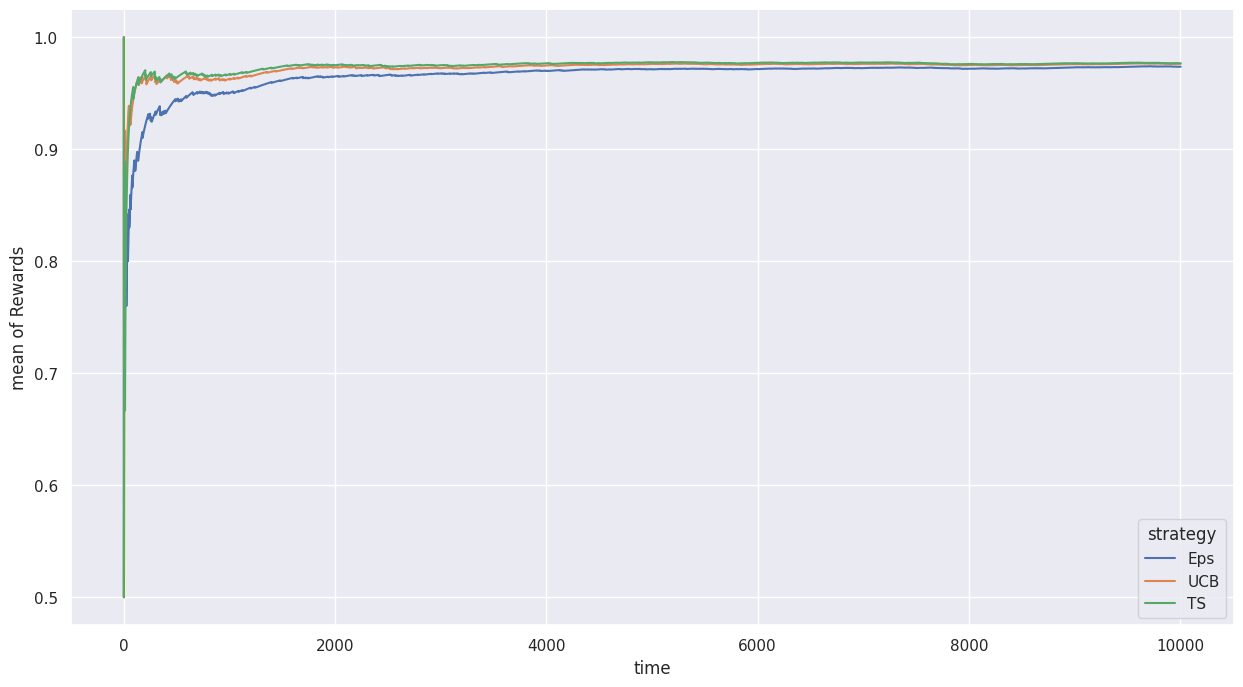

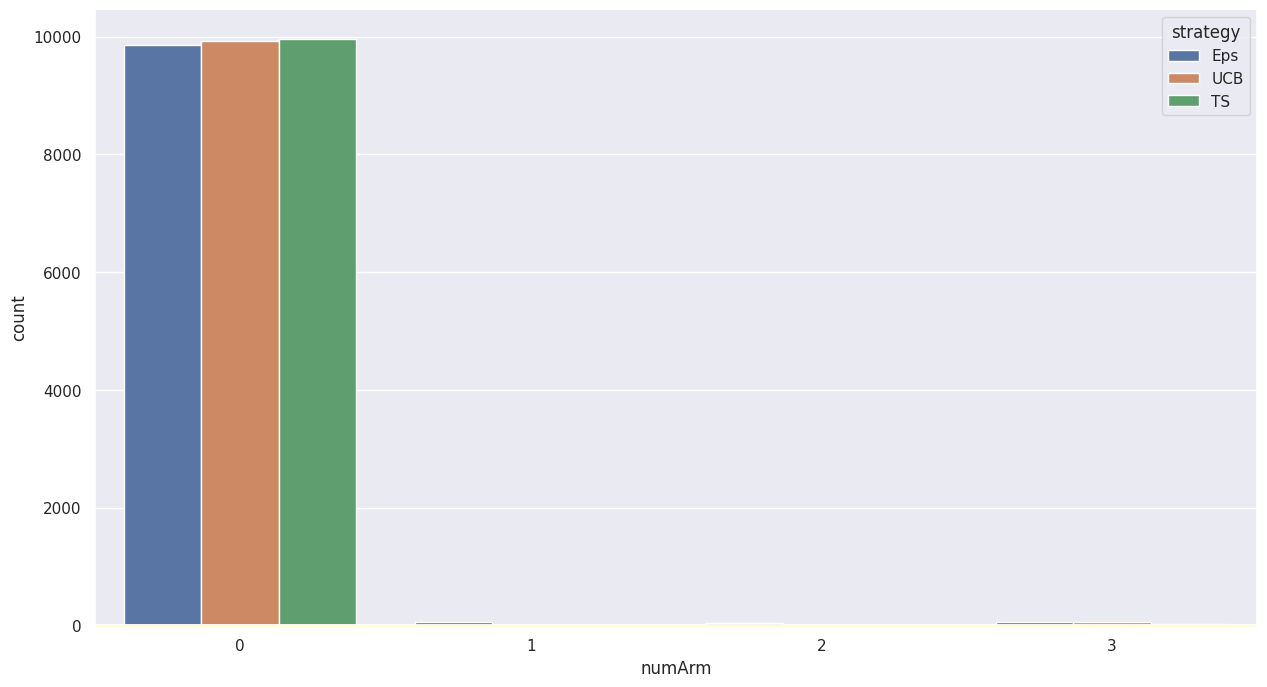

In [35]:
# from here standard
strategies = ["Eps","UCB","TS"]

DataPlot_Intox = pl.concat(
    [
        globals()[f"gr{strat}_Intox"].getHistoryRewards()
        .sort("time")
        .select(
            pl.col("time"),
            (pl.col("reward").cum_sum() / pl.col("time")).alias("mean of Rewards"),
            pl.col("numArm"),
            pl.lit(strat).alias("strategy")
        )
        for strat in strategies
    ]
)

print(DataPlot_Intox)

plt.figure(1, figsize=[15, 8])
# Apply the default theme

sns.set_theme()

# Create a visualization
g = sns.lineplot(data=DataPlot_Intox, x="time", y="mean of Rewards", hue="strategy")


# Build a rectangle for initialization phase
left, width = 0, (numArms + 1)
bottom, top = min(DataPlot_Intox.get_column("mean of Rewards")), max(
    DataPlot_Intox.get_column("mean of Rewards")
)
right = left + width
height = top - bottom
p = plt.Rectangle((left, bottom), width, height, fill=True, color="yellow")

p.set_clip_on(False)
g.add_patch(p)

plt.show()


### second figure

plt.figure(2, figsize=[15, 8])
# Apply the default theme

sns.set_theme()

g = sns.countplot(data=DataPlot_Intox, x="numArm", hue="strategy")

# Build a rectangle for initialization phase
left, width = -.5, (numArms)
bottom, top = 0, 1
right = left + width
height = top - bottom
p = plt.Rectangle((left, bottom), width, height, fill=True, color="yellow")
p.set_clip_on(False)

# Apply the default theme
g.axes.add_patch(p)

plt.show()

## Confronto performance Intoxicazione (max 1 pag.), 5pts

> Si commentino le differenti performance delle tre strategie.

---
<!-- Inizia qui la risposta -->
In questo scenario, la funzione di reward è stata modificata per includere una forte penalità per i valori di reward inferiori a $0.2$. L'obiettivo non è più solo massimizzare il guadagno, ma anche garantire la sicurezza del paziente.

**Epsilon-Greedy ($\epsilon$-Greedy)**: 
È la strategia che presenta le criticità maggiori in ambito clinico. A causa dell'esplorazione casuale fissa ($\epsilon$), l'algoritmo continuerà a selezionare le leve tossiche con frequenza costante. Questo comporta un numero di eventi di intossicazione elevato rispetto alle altre strategie.

**UCB1 (Upper Confidence Bound)**:
Ha una buona capacità di adattamento. Non appena una leva restituisce un reward molto basso, il limite superiore dell'intervallo di confidenza ($UCB_i$) crolla drasticamente. L'algoritmo smette di testare quella leva, privilegiando quelle con una media di sicurezza alta.

**Thompson Sampling (TS)**:
E' la strategia più efficace ed etica. Grazie alla distribuzione a posteriori, TS aggiorna istantaneamente la probabilità che una leva sia ottimale. Una singola penalità sposta la distribuzione verso valori minimi, rendendo la probabilità di campionare quella leva quasi nulla. TS riesce a isolare le cure tossiche nel minor numero di step.


Mentre $\epsilon$-greedy accetta un rischio costante, UCB1 e TS minimizzano la probabilità di somministrare farmaci pericolosi.
Nello scenario con intossicazione TS e UCB1 convergono meglio rispetto alla greedy.
<!-- Termina qui la risposta -->
---